# One-way vs two-way terrain-following propagators over slopes

Reference comparison for beams reflected by conducting and impedance slopes.
All solvers share the same physical experiment: a 300 MHz Gaussian beam
directed at a negative elevation angle ``alpha`` illuminates a plane slope
``z = x tan(theta_s)``; the exact reference field is

* for a **PEC** slope, the complex-source-point (CSP) beam plus its mirror
  image in the slope line (an exact solution of the Helmholtz equation with
  ``u = 0`` on the slope);
* for an **impedance** (Leontovich) ground, a plane-wave superposition in
  which every plane wave is reflected with the exact Leontovich coefficient
  ``R(phi) = (sin phi - D)/(sin phi + D)``.

The solvers:

* **one-way TF** — the terrain-following rational (Padé) PE of
  Lytaev 2018/2020, marching from the starting trajectory;
* **two-way TF (Bremmer)** — the forward–backward splitting of
  ``two_way_helmholtz_tf.tex`` implemented in
  ``pywaveprop/helmholtz_two_way_jax.py``: the split state is marched with the
  one-way rational chain (``G+``) and its conjugated, coefficient-negated
  approximant (``G-``), the coupling ``R`` is applied on the transition-layer
  rows through the discrete ``B^(±1/4)`` flux-chain actions, and the physical
  field is ``psi = r^-1/2 Q^-1 (u+ + u-)``;
* **staircase** — the classical piecewise-linear staircase FD PE with an
  absorbing layer at the top.

The terrain-following domain is extended left of ``x = 0`` (``x_min_m``) so
that the descent drift through the transition layer does not push the
reflection region outside the computational domain: the reflected wave is then
produced by the solver itself, from the incident field prescribed on the
starting trajectory.


In [1]:
import sys, os, time, json
sys.path.insert(0, os.path.abspath('../..'))            # repository root
sys.path.insert(0, os.path.abspath('../../scripts'))    # scripts/
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import hankel1
import jax.numpy as jnp
from pywaveprop.helmholtz_common import HelmholtzMeshParams2D
from pywaveprop.helmholtz_tf_jax import TerrainFollowingHelmholtzPropagator, TFMedium
from pywaveprop.helmholtz_two_way_jax import TwoWayTerrainFollowingPropagator
from pywaveprop.helmholtz_ssf_jax import impedance_alpha
from pywaveprop.terrain_transform import OrthogonalTerrainMap
from tap_impedance_staircase import staircase, leontovich_d
from terrain_transform_impedance import GROUNDS, exact_field as impedance_exact

FREQ = 3e8
K0 = 2 * np.pi * FREQ / 3e8
plt.rcParams['figure.dpi'] = 90
print('setup ok')

setup ok


## Exact reference fields

For the PEC slope the reference is the CSP beam plus its mirror image; for the
impedance ground it is the angular-spectrum superposition with the Leontovich
reflection coefficient of every plane wave
(``terrain_transform_impedance.exact_field``).

In [2]:
import terrain_transform_impedance as _tti

def impedance_exact_shifted(th, eps, pol, xs, zs):
    '''The impedance angular-spectrum exact field with the waist moved to (xs, zs).'''
    old = (_tti.XS, _tti.ZS)
    _tti.XS, _tti.ZS = xs, zs
    try:
        return _tti.exact_field(th, eps, pol)
    finally:
        _tti.XS, _tti.ZS = old

def make_pec_exact(xs, zs, inc_deg, slope_deg):
    '''CSP beam + mirror image: exact total field above a PEC slope.'''
    th = np.radians(slope_deg); s = np.tan(th)
    n = np.array([-s, 1.0]) / np.hypot(s, 1.0)
    refl = np.eye(2) - 2 * np.outer(n, n)
    ri = refl @ np.array([xs, zs])
    ei = refl @ np.array([np.cos(np.radians(inc_deg)), np.sin(np.radians(inc_deg))])
    def csp(x, z, sx, sz, ang):
        r = np.sqrt((x - sx - 1j * 100.0 * np.cos(ang)) ** 2
                    + (z - sz - 1j * 100.0 * np.sin(ang)) ** 2)
        return 1j / 4 * hankel1(0, K0 * r)
    nm = np.abs(csp(np.array([0.]), np.array([zs]), xs, zs, np.radians(inc_deg))
                - csp(np.array([0.]), np.array([zs]), ri[0], ri[1],
                      np.arctan2(ei[1], ei[0])))[0]
    def exact(x, z):
        x = np.asarray(x, float); z = np.asarray(z, float)
        return (csp(x, z, xs, zs, np.radians(inc_deg))
                - csp(x, z, ri[0], ri[1], np.arctan2(ei[1], ei[0]))) / nm
    return exact

print('exact builders ok')

exact builders ok


## The experiment runner

One case = (ground type, slope angle, beam elevation angle).  The
terrain-following ``xi`` domain starts left of the illuminated patch
(``x_min`` compensates the trajectory drift through the transition layer), so
the reflection spot lies inside the domain for both terrain-following solvers;
the staircase covers the same rectangle on a Cartesian cut grid with an
absorbing layer above ``z_top``.  Every solver is compared with the exact
field on its own output grid, above the slope (2 m margin) and below the
absorber/top row.

In [3]:
def run_case(cfg):
    t0 = time.time()
    th = float(cfg['slope']); inc = float(cfg['inc'])
    s = np.tan(np.radians(th))
    pec = (cfg['ground'] == 'PEC')
    pol = 'H' if pec else cfg.get('pol', 'V')
    eps = None if pec else GROUNDS[cfg['ground']]
    x_max = float(cfg.get('x_max', 600.0))
    relief = s * x_max
    L = 2.2 * relief
    z_ref = relief
    z_top = relief + max(400.0, L + 100.0)
    z_size = z_top - z_ref
    x_min = -(np.sin(np.radians(th)) * L * 0.6 + 60.0)
    dxi_out, deta_out = 2.5, 0.25

    # the beam waist sits ~300 m upstream of the extended domain: the solvers
    # start from a formed beam and the source near-field is not transported
    xs0 = -50.0 - 300.0 * np.cos(np.radians(inc))
    zs0 = 30.0 - 300.0 * np.sin(np.radians(inc))
    exact = (make_pec_exact(xs0, zs0, inc, th) if pec
             else impedance_exact_shifted(th, eps, pol, xs0, zs0))
    xb = np.linspace(x_min - 1600.0, x_max + 1600.0, 4001)
    tmap = OrthogonalTerrainMap(xb, s * xb, x_max_m=x_max, transition_m=L, z_ref_m=z_ref,
                                smoothing_m=0.0, mirror_start=False, dx_fine_m=0.5,
                                pad_m=1500.0, x_min_m=x_min)
    med = TFMedium(k2_above=lambda x, z: np.full(np.shape(z), K0 ** 2, dtype=complex))
    mp = HelmholtzMeshParams2D(x_size_m=x_max - x_min, z_size_m=z_size,
                               dx_output_m=dxi_out, dz_output_m=deta_out)
    lower = {} if pec else dict(lower_bc='impedance',
                                lower_impedance_alpha=impedance_alpha(K0, eps, pol),
                                impedance_closure='compact')
    kz_max = min(1.15 * K0 * np.sin(np.radians(abs(inc) + 2 * th + 5.0)), 0.97 * K0)
    res = dict(cfg=cfg, s=s, x_min=x_min, x_max=x_max, z_top=z_top)

    # ---- one-way terrain-following
    p1 = TerrainFollowingHelmholtzPropagator.create(FREQ, tmap, med, kz_max, (K0, K0), 1e-2, mp,
                                                    rational_approx_order=(7, 8),
                                                    upper_bc='nlbc', **lower)
    x0, z0 = p1.initial_points()
    t = time.time()
    u1 = np.asarray(p1.compute(jnp.asarray(exact(x0, z0))))
    res['time_one_way'] = time.time() - t
    xo1, zo1 = p1.output_metrics()                     # already (n_x, n_z) grids
    # the solver's reduced field is referenced to the march arc xi - x_min
    ue1 = exact(xo1, zo1) * np.exp(-1j * p1.beta * (np.asarray(p1.x_output_grid()) - p1.x_min_m)[:, None])
    m1 = (zo1 >= s * xo1 + 2.0)
    res['one_way'] = dict(x=xo1, z=zo1, u=u1, ue=ue1, m=m1, beta=float(p1.beta),
                          err=float(np.abs(u1 - ue1)[m1].max() / np.abs(ue1)[m1].max()),
                          grid=dict(dx=float(p1.dx_m), dz=float(p1.dz_m),
                                    x_n=int(p1.x_n), z_n=int(p1.z_n)))

    # ---- two-way terrain-following (Bremmer)
    p2 = TwoWayTerrainFollowingPropagator.create(FREQ, tmap, med, kz_max, (K0, K0), 1e-2, mp,
                                                 rational_approx_order=(7, 8),
                                                 upper_bc='nlbc', flux_order=2, **lower)
    t = time.time()
    psi2, tp2, tm2, _ = p2.compute(jnp.asarray(exact(x0, z0)),
                                   n_bremmer=int(cfg.get('n_bremmer', 3)))
    res['time_two_way'] = time.time() - t
    psi2 = np.asarray(psi2)
    xo2, zo2 = p2.output_metrics()
    ue2 = exact(xo2, zo2) * np.exp(-1j * p2.beta * (np.asarray(p2.x_output_grid()) - p2.x_min_m)[:, None])
    m2 = (zo2 >= s * xo2 + 2.0)
    res['two_way'] = dict(x=xo2, z=zo2, u=psi2, ue=ue2, m=m2, beta=float(p2.beta),
                          err=float(np.abs(psi2 - ue2)[m2].max() / np.abs(ue2)[m2].max()),
                          grid=dict(dx=float(p2.dx_m), dz=float(p2.dz_m),
                                    x_n=int(p2.x_n), z_n=int(p2.z_n)))

    # ---- staircase (marches the same incident beam as the other solvers)
    import tap_impedance_staircase as _tis
    _tis.exact_field = lambda slope_deg, eps, pol: exact
    t = time.time()
    xo3, zo3, u3, _, _ = staircase(th, None if pec else eps, None if pec else pol,
                                   dz=0.05, dx=2.5, x_max=x_max, dx_out=dxi_out, dz_out=deta_out)
    res['time_staircase'] = time.time() - t
    X3, Z3 = np.meshgrid(xo3, zo3, indexing='ij')
    ue3 = exact(X3, Z3) * np.exp(-1j * K0 * X3)
    m3 = (Z3 >= s * X3 + 2.0) & (Z3 < z_top - 50.0)
    res['staircase'] = dict(x=xo3, z=zo3, u=u3, ue=ue3, m=m3,
                            err=float(np.abs(u3 - ue3)[m3].max() / np.abs(ue3)[m3].max()),
                            grid=dict(dx=2.5, dz=0.05, x_n=int(len(xo3)), z_n=int(len(zo3))))

    res['ue'] = ue2                       # exact field on the two-way output grid
    res['total_time'] = time.time() - t0
    res['name'] = cfg['name']
    return res

print('runner ok')

runner ok


## Cases

PEC slopes at 10/20/30 degrees with the beam at $-10^\circ$ (reflected beams
at $30/50/70^\circ$), a steeper incidence on the 20-degree slope (beam
$-25^\circ$, grazing $5^\circ$, reflected $65^\circ$), and two V-polarization
wet-ground cases (the incidence is near the pseudo-Brewster angle, so the
physical reflection is weak).

In [4]:
%matplotlib inline
import pickle
import os as _os
CASES = [
    dict(name='PEC, slope 30 deg, beam -10 deg (reflected 70 deg)',
         ground='PEC', slope=30.0, inc=-10.0, x_max=400.0),
    dict(name='PEC, slope 20 deg, beam -10 deg (reflected 50 deg)',
         ground='PEC', slope=20.0, inc=-10.0, x_max=500.0),
    dict(name='PEC, slope 10 deg, beam -10 deg (reflected 30 deg)',
         ground='PEC', slope=10.0, inc=-10.0, x_max=600.0),
    dict(name='PEC, slope 20 deg, beam -25 deg (reflected 65 deg, grazing 5 deg)',
         ground='PEC', slope=20.0, inc=-25.0, x_max=500.0),
    dict(name='wet ground V, slope 10 deg, beam -5 deg (reflected 25 deg, grazing 15 deg)',
         ground='wet ground', slope=10.0, inc=-5.0, x_max=600.0, pol='V'),
    dict(name='wet ground V, slope 20 deg, beam -5 deg (reflected 35 deg, grazing 25 deg)',
         ground='wet ground', slope=20.0, inc=-5.0, x_max=600.0, pol='V'),
]
CACHE = os.path.abspath('../../papers/tap2026/two_way_case_results.pkl')
if _os.path.exists(CACHE) and _os.environ.get('TWO_WAY_RERUN') != '1':
    with open(CACHE, 'rb') as f:
        RESULTS = pickle.load(f)
    for r, cfg in zip(RESULTS, CASES):
        r['cfg'] = cfg                     # refresh names/metadata from the notebook
        # rebuild the reference with the arc-referenced envelope and re-measure
        th = float(cfg['slope']); inc = float(cfg['inc'])
        s = np.tan(np.radians(th))
        pec = (cfg['ground'] == 'PEC')
        xs0 = -50.0 - 300.0 * np.cos(np.radians(inc))
        zs0 = 30.0 - 300.0 * np.sin(np.radians(inc))
        exact = (make_pec_exact(xs0, zs0, inc, th) if pec
                 else impedance_exact_shifted(th, GROUNDS[cfg['ground']],
                                              cfg.get('pol', 'V'), xs0, zs0))
        x_min = float(r['x_min'])
        for tag in ('one_way', 'two_way'):
            g = r[tag]['grid']; beta = r[tag]['beta']
            n_out = r[tag]['x'].shape[0]
            dxi_out = (float(r['x_max']) - x_min) / (n_out - 1)   # the output xi spacing
            xi = x_min + np.arange(n_out) * dxi_out
            ue = exact(r[tag]['x'], r[tag]['z']) * np.exp(-1j * beta * (xi - x_min)[:, None])
            m = (r[tag]['z'] >= s * r[tag]['x'] + 2.0)
            r[tag]['ue'] = ue; r[tag]['m'] = m
            r[tag]['err'] = float(np.abs(r[tag]['u'] - ue)[m].max() / np.abs(ue)[m].max())
    print('loaded cached results for', len(RESULTS), 'cases; '
          'set TWO_WAY_RERUN=1 to recompute')
    # the staircase is cheap: re-march it so its panel matches the current
    # incident beam (the cached staircase fields may be stale)
    for r in RESULTS:
        cfg = r['cfg']; th = float(cfg['slope']); inc = float(cfg['inc'])
        s = np.tan(np.radians(th))
        pec = (cfg['ground'] == 'PEC')
        pol = 'H' if pec else cfg.get('pol', 'V')
        eps = None if pec else GROUNDS[cfg['ground']]
        xs0 = -50.0 - 300.0 * np.cos(np.radians(inc))
        zs0 = 30.0 - 300.0 * np.sin(np.radians(inc))
        exact = (make_pec_exact(xs0, zs0, inc, th) if pec
                 else impedance_exact_shifted(th, eps, pol, xs0, zs0))
        import tap_impedance_staircase as _tis
        _tis.exact_field = lambda *a, **k: exact
        t = time.time()
        xo3, zo3, u3, _, _ = staircase(th, None if pec else eps, None if pec else pol,
                                       dz=0.05, dx=2.5, x_max=float(cfg['x_max']),
                                       dx_out=2.5, dz_out=0.25)
        X3, Z3 = np.meshgrid(xo3, zo3, indexing='ij')
        ue3 = exact(X3, Z3) * np.exp(-1j * K0 * X3)
        m3 = (Z3 >= s * X3 + 2.0) & (Z3 < r['z_top'] - 50.0)
        r['staircase'] = dict(x=xo3, z=zo3, u=u3, ue=ue3, m=m3,
                              err=float(np.abs(u3 - ue3)[m3].max() / np.abs(ue3)[m3].max()),
                              grid=dict(dx=2.5, dz=0.05, x_n=int(len(xo3)), z_n=int(len(zo3))))
        r['time_staircase'] = time.time() - t
    print('staircase re-marched for all cases')
else:
    RESULTS = []
    for i, cfg in enumerate(CASES):
        print(f'[{i + 1}/{len(CASES)}] {cfg["name"]} ...', flush=True)
        r = run_case(cfg)
        RESULTS.append(r)
        print(f'   one-way {r["one_way"]["err"]:.3g} | two-way {r["two_way"]["err"]:.3g} | '
              f'staircase {r["staircase"]["err"]:.3g} | grids '
              f'TF {r["one_way"]["grid"]["x_n"]}x{r["one_way"]["grid"]["z_n"]}, '
              f'2W {r["two_way"]["grid"]["x_n"]}x{r["two_way"]["grid"]["z_n"]}, '
              f'stair {r["staircase"]["grid"]["x_n"]}x{r["staircase"]["grid"]["z_n"]} | '
              f'{r["total_time"]:.0f} s', flush=True)
    _os.makedirs(os.path.dirname(CACHE), exist_ok=True)
    with open(CACHE, 'wb') as f:
        pickle.dump(RESULTS, f)
    print('results cached to', CACHE)
with open('two_way_results_metrics.json', 'w') as f:
    metrics = []
    for r in RESULTS:
        metrics.append(dict(name=r['name'], x_min=r['x_min'], x_max=r['x_max'],
                            one_way=dict(err=r['one_way']['err'], grid=r['one_way']['grid']),
                            two_way=dict(err=r['two_way']['err'], grid=r['two_way']['grid']),
                            staircase=dict(err=r['staircase']['err'], grid=r['staircase']['grid']),
                            time_one_way=r['time_one_way'], time_two_way=r['time_two_way'],
                            time_staircase=r['time_staircase']))
    json.dump(metrics, f, indent=1)
print('metrics written to two_way_results_metrics.json')

[1/6] PEC, slope 30 deg, beam -10 deg (reflected 70 deg) ...


terrain-following map: h_xi in [0.998, 1.003], r in [0.748, 2.131]
rational_approx_order: (7, 8), beta: 3.491276237055631, dxi: 0.8333333333333334, deta: 0.007352941176470588


terrain-following map: h_xi in [0.998, 1.003], r in [0.748, 2.131]
rational_approx_order: (7, 8), beta: 3.491276237055631, dxi: 0.8333333333333334, deta: 0.007352941176470588


   one-way 0.00167 | two-way 0.184 | staircase 0.614 | grids TF 736x82699, 2W 736x82699, stair 161x3357 | 266 s


[2/6] PEC, slope 20 deg, beam -10 deg (reflected 50 deg) ...


terrain-following map: h_xi in [0.999, 1.002], r in [0.865, 2.010]
rational_approx_order: (7, 8), beta: 3.9350035223891138, dxi: 1.25, deta: 0.009615384615384616


... (15 outputs left out)

terrain-following map: h_xi in [0.998, 1.003], r in [0.856, 1.990]
rational_approx_order: (7, 8), beta: 4.263990255422093, dxi: 1.25, deta: 0.0125


terrain-following map: h_xi in [0.998, 1.003], r in [0.856, 1.990]
rational_approx_order: (7, 8), beta: 4.263990255422093, dxi: 1.25, deta: 0.0125


   one-way 0.00023 | two-way 0.0577 | staircase 0.252 | grids TF 608x46437, 2W 608x46437, stair 241x3196 | 653 s


results cached to /home/developer/pywaveprop/wave-propagation/papers/tap2026/two_way_case_results.pkl
metrics written to two_way_results_metrics.json


## Fields, errors and grids, case by case

For every case: the exact field, the three solvers, and the pointwise error
maps (all panels on the respective solver's own output grid), followed by the
grid sizes and run times.

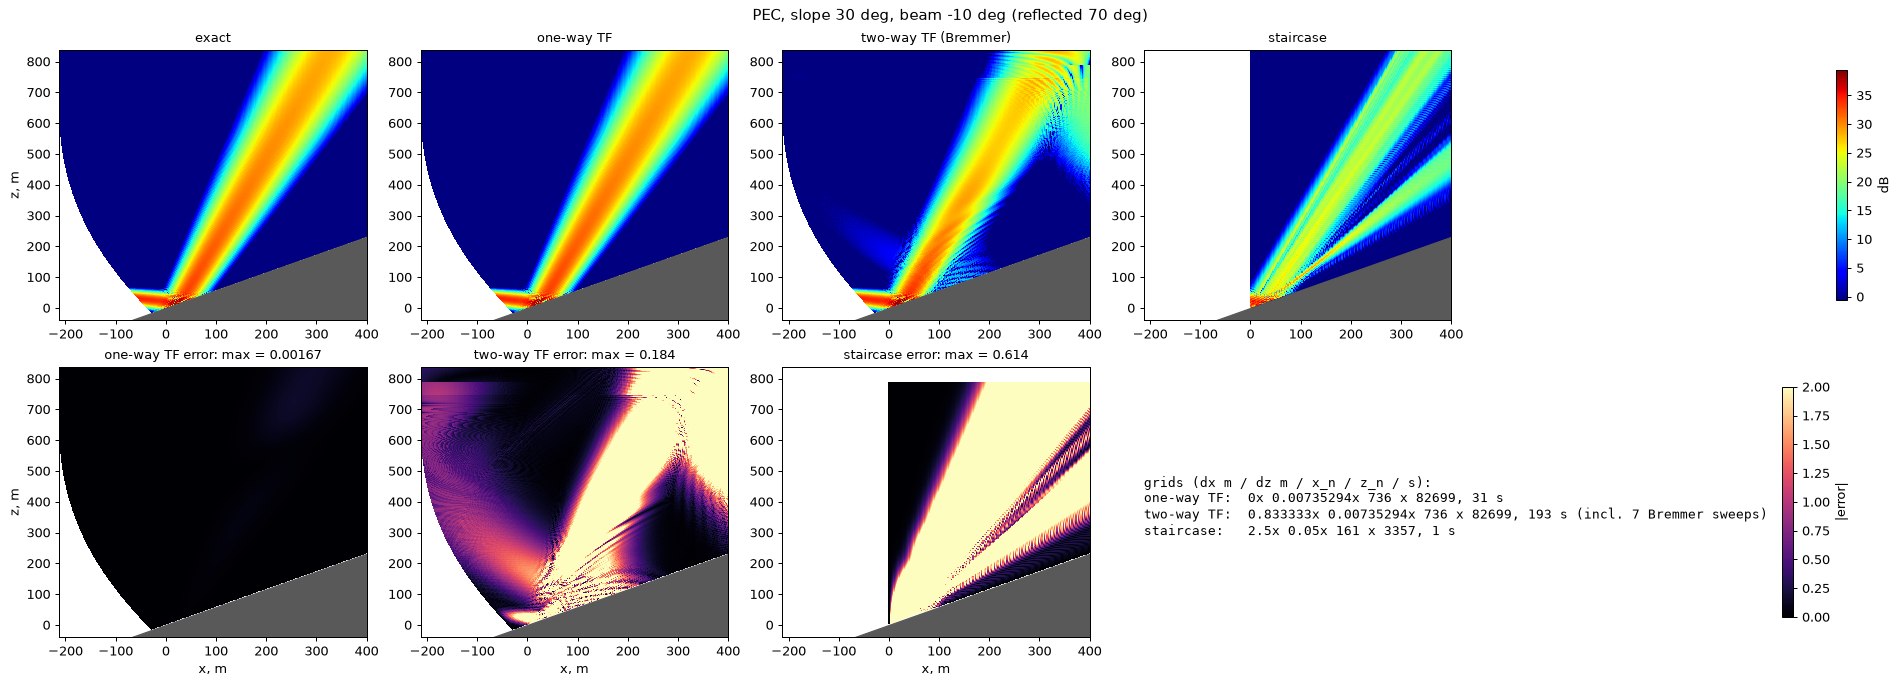

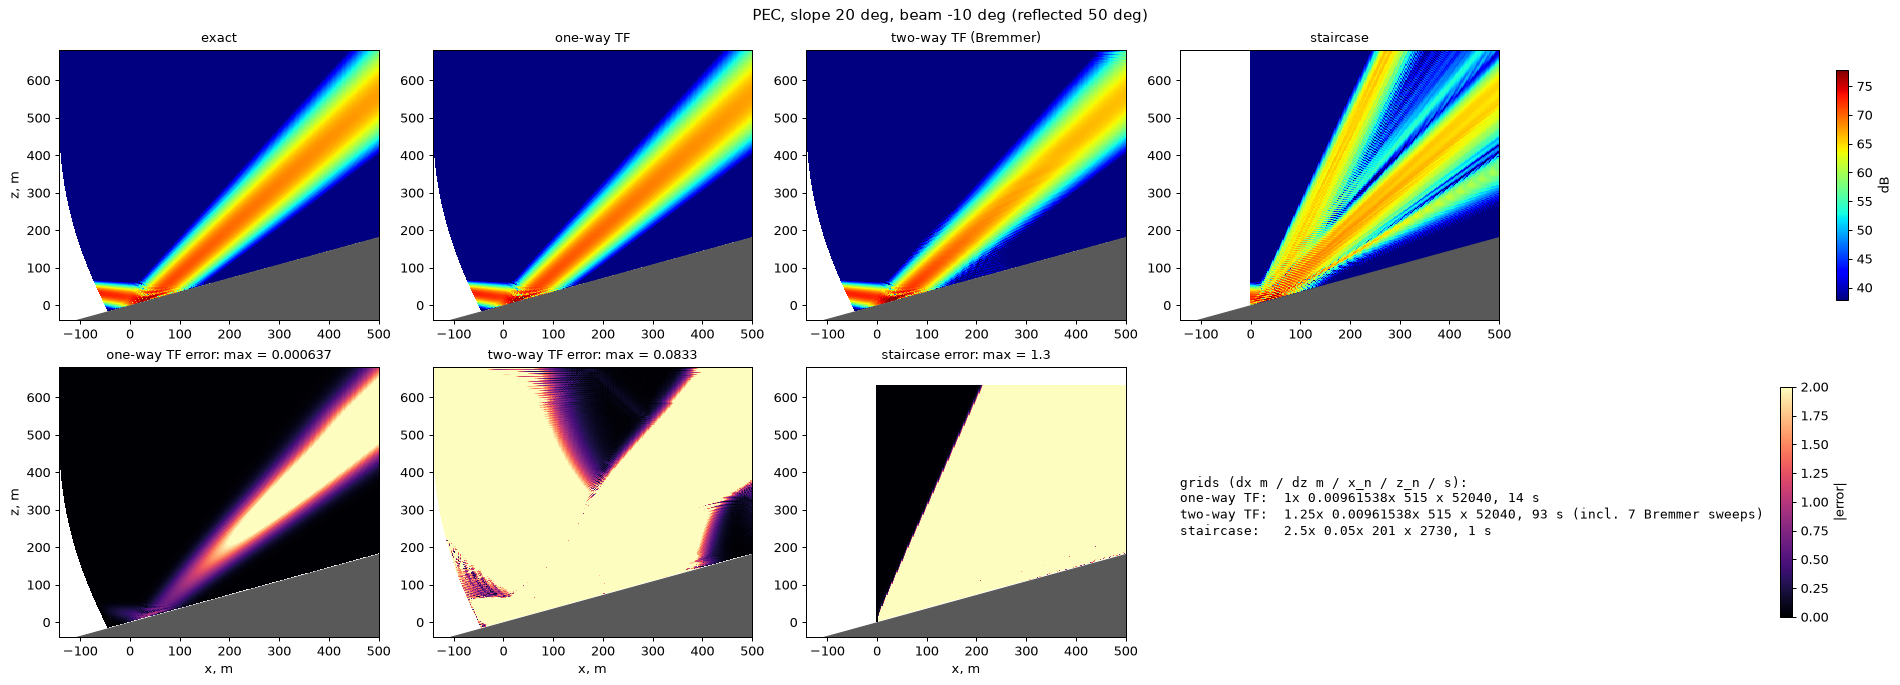

/tmp/ipykernel_662464/3486080457.py:14: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(X, Z, 20 * np.log10(np.abs(u) + 1e-12),
/tmp/ipykernel_662464/3486080457.py:27: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(X, Z, np.where(meta['m'], e, np.nan),


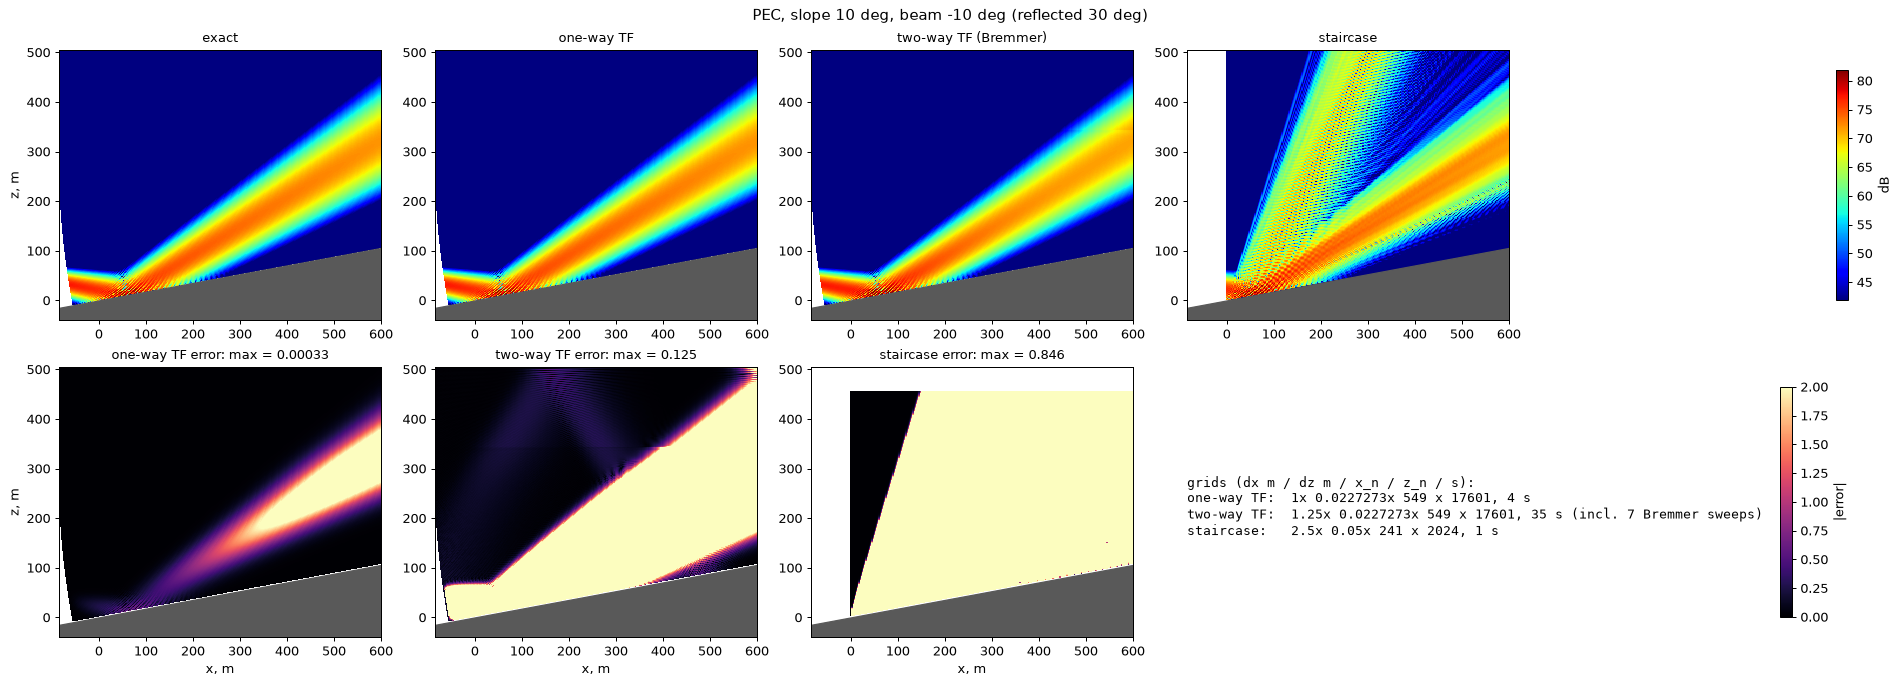

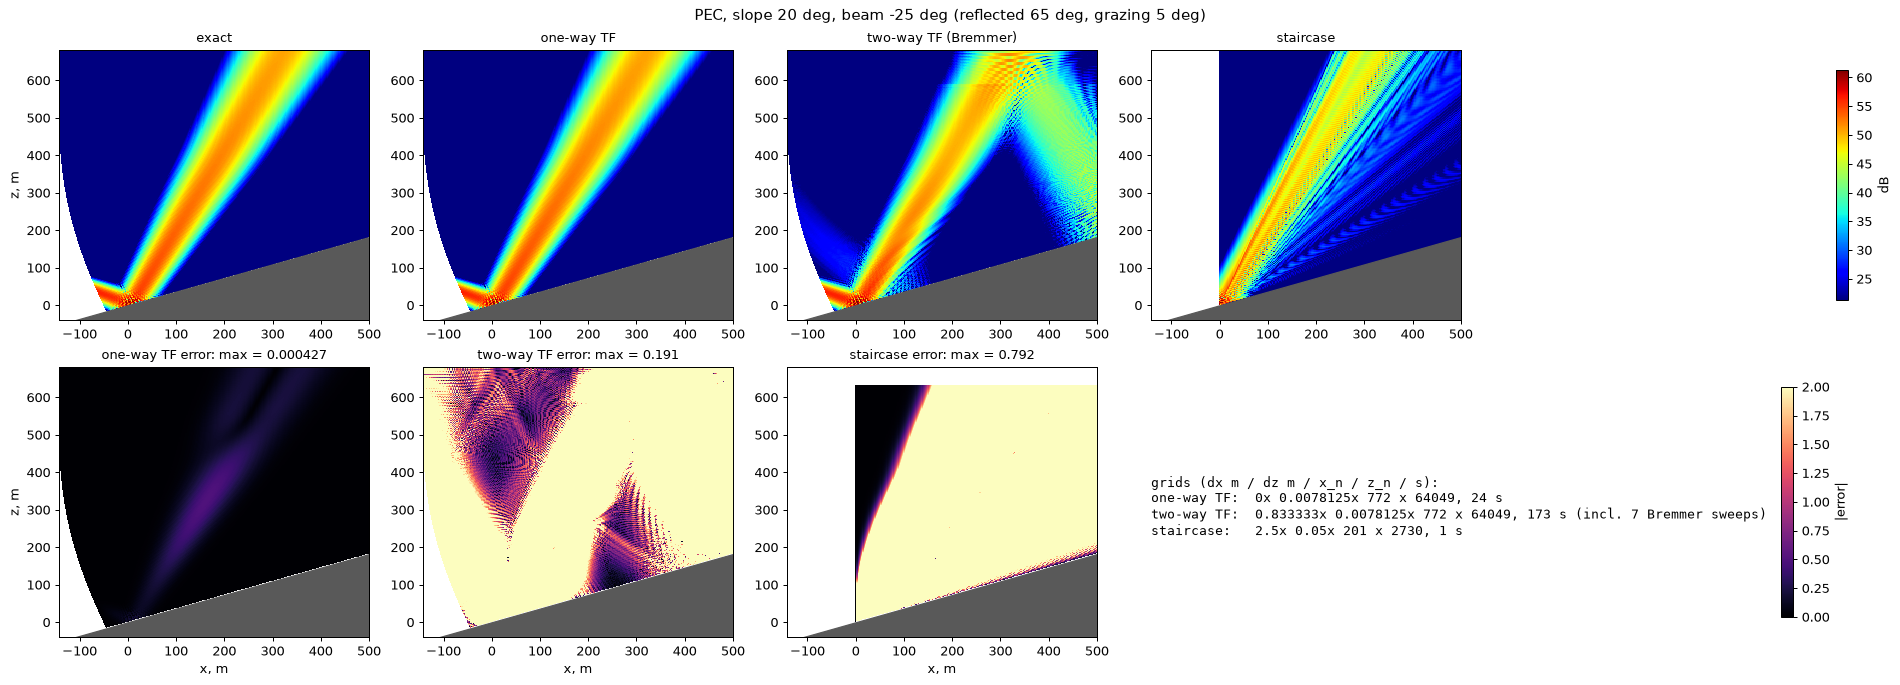

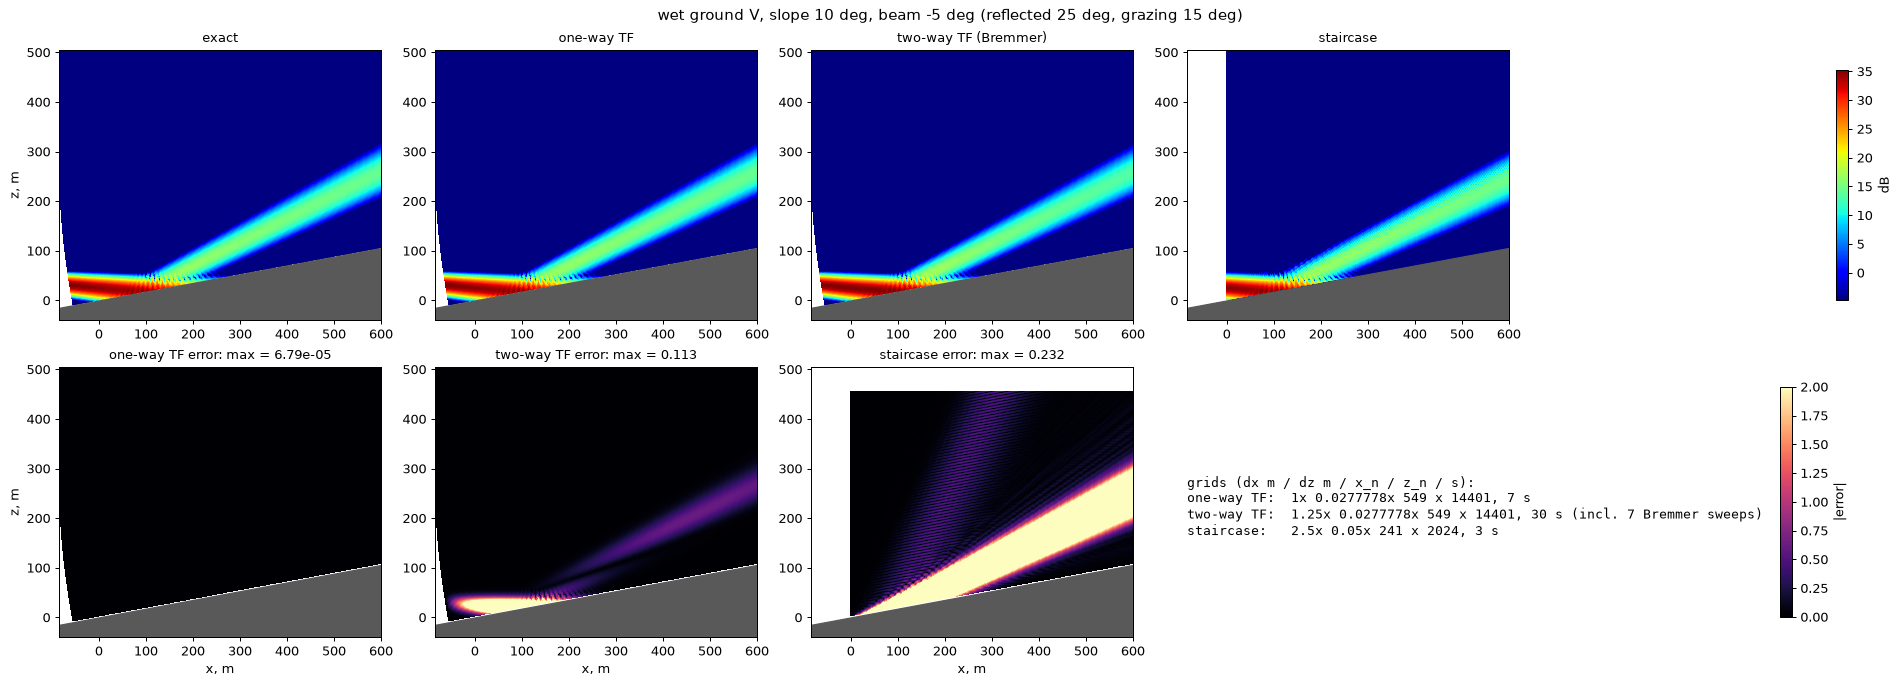

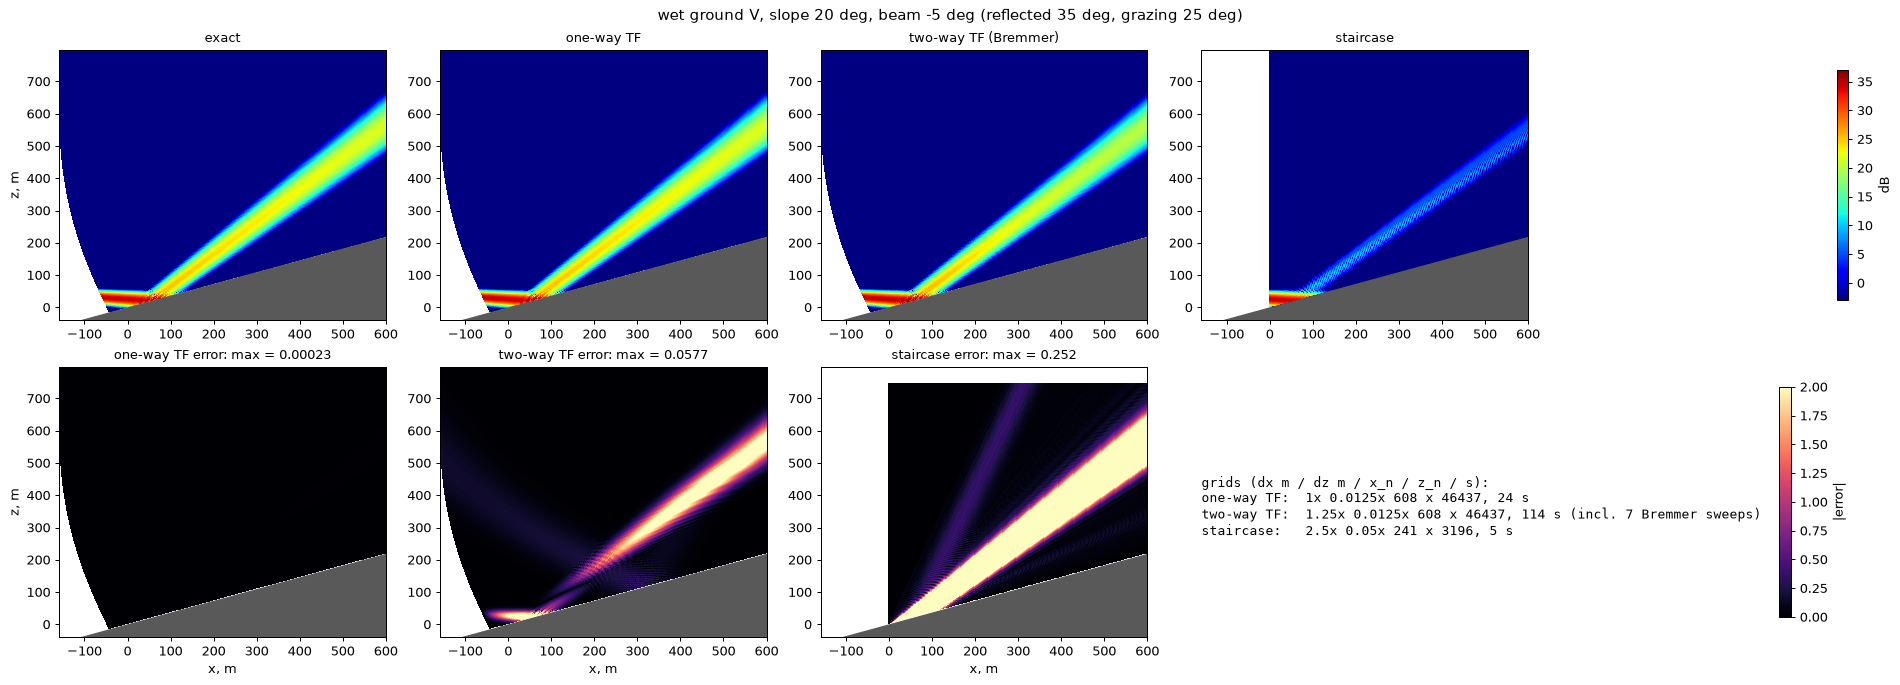

In [5]:
def case_figure(r):
    cfg = r['cfg']; s = r['s']
    x_min, x_max = r['x_min'], r['x_max']
    panels = [('exact', r['ue'], None),
              ('one-way TF', r['one_way']['u'], r['one_way']),
              ('two-way TF (Bremmer)', r['two_way']['u'], r['two_way']),
              ('staircase', r['staircase']['u'], r['staircase'])]
    vm = 20 * np.log10(np.abs(np.asarray(r['ue'])).max())
    fig, axes = plt.subplots(2, 4, figsize=(21, 7.5), constrained_layout=True)
    for ax, (title, u, meta) in zip(axes.ravel()[:4], panels):
        X, Z = (meta['x'], meta['z']) if meta else (r['two_way']['x'], r['two_way']['z'])
        if X.ndim == 1:
            X, Z = np.meshgrid(X, Z, indexing='ij')
        pc = ax.pcolormesh(X, Z, 20 * np.log10(np.abs(u) + 1e-12),
                           vmin=vm - 40, vmax=vm, cmap='jet', shading='auto')
        ax.fill_between([x_min, x_max], [-40, -40], [s * x_min, s * x_max], color='0.35')
        ax.set_xlim(x_min, x_max); ax.set_ylim(-40, r['z_top']); ax.set_title(title, fontsize=10)
    fig.colorbar(pc, ax=axes[0, :], label='dB', shrink=0.85)
    for ax, (title, meta) in zip(axes.ravel()[4:7],
                                 [('one-way TF error', r['one_way']),
                                  ('two-way TF error', r['two_way']),
                                  ('staircase error', r['staircase'])]):
        X, Z = meta['x'], meta['z']
        if X.ndim == 1:
            X, Z = np.meshgrid(X, Z, indexing='ij')
        e = np.abs(np.asarray(meta['u']) - np.asarray(meta['ue']))
        pc = ax.pcolormesh(X, Z, np.where(meta['m'], e, np.nan),
                           vmin=0, vmax=2.0, cmap='magma', shading='auto')
        ax.fill_between([x_min, x_max], [-40, -40], [s * x_min, s * x_max], color='0.35')
        ax.set_xlim(x_min, x_max); ax.set_ylim(-40, r['z_top'])
        ax.set_title(f'{title}: max = {meta["err"]:.3g}', fontsize=10)
    fig.colorbar(pc, ax=axes[1, 3], label='|error|', shrink=0.85)
    gtxt = '\n'.join([
        'grids (dx m / dz m / x_n / z_n / s):',
        'one-way TF:  %dx %gx %d x %d, %.0f s' % (r['one_way']['grid']['dx'], r['one_way']['grid']['dz'],
                                                  r['one_way']['grid']['x_n'], r['one_way']['grid']['z_n'],
                                                  r['time_one_way']),
        'two-way TF:  %gx %gx %d x %d, %.0f s (incl. %d Bremmer sweeps)'
            % (r['two_way']['grid']['dx'], r['two_way']['grid']['dz'],
               r['two_way']['grid']['x_n'], r['two_way']['grid']['z_n'],
               r['time_two_way'], 2 * cfg.get('n_bremmer', 3) + 1),
        'staircase:   %gx %gx %d x %d, %.0f s' % (r['staircase']['grid']['dx'], r['staircase']['grid']['dz'],
                                                  r['staircase']['grid']['x_n'], r['staircase']['grid']['z_n'],
                                                  r['time_staircase']),
    ])
    axes[1, 3].axis('off')
    axes[1, 3].text(0.0, 0.6, gtxt, fontsize=10, family='monospace', va='top')
    axes[1, 0].set_ylabel('z, m')
    for ax in axes.ravel()[4:]:
        ax.set_xlabel('x, m')
    axes[0, 0].set_ylabel('z, m')
    fig.suptitle(cfg['name'], fontsize=12)
    return fig

for r in RESULTS:
    case_figure(r)
    plt.show()

## Summary: errors and grid sizes

In [6]:
hdr = (f'{"case":52s} | {"grazing":>7s} {"refl":>5s} | '
       f'{"1-way err":>9s} {"2-way err":>9s} {"stair err":>9s}')
print(hdr); print('-' * len(hdr))
for r in RESULTS:
    cfg = r['cfg']; th = cfg['slope']; inc = abs(cfg['inc'])
    grazing = th + abs(cfg['inc'])
    refl = 2 * th + abs(cfg['inc'])
    print(f'{cfg["name"][:52]:52s} | {grazing:6.1f}d {refl:4.0f}d | '
          f'{r["one_way"]["err"]:9.3g} {r["two_way"]["err"]:9.3g} {r["staircase"]["err"]:9.3g}')
print()
print('grid sizes (dx m, dz m, x_n, z_n) and run times (s):')
for r in RESULTS:
    print(f'  {r["cfg"]["name"][:46]:46s}')
    for tag in ('one_way', 'two_way', 'staircase'):
        g = r[tag]['grid']
        print(f'    {tag:10s} dx={g["dx"]:7.4g} dz={g["dz"]:7.4g} x_n={g["x_n"]:6d} '
              f'z_n={g["z_n"]:6d}  time={r["time_" + tag]:7.1f} s')

case                                                 | grazing  refl | 1-way err 2-way err stair err
----------------------------------------------------------------------------------------------------
PEC, slope 30 deg, beam -10 deg (reflected 70 deg)   |   40.0d   70d |   0.00167     0.184     0.614
PEC, slope 20 deg, beam -10 deg (reflected 50 deg)   |   30.0d   50d |  0.000637    0.0833       1.3
PEC, slope 10 deg, beam -10 deg (reflected 30 deg)   |   20.0d   30d |   0.00033     0.125     0.846
PEC, slope 20 deg, beam -25 deg (reflected 65 deg, g |   45.0d   65d |  0.000427     0.191     0.792
wet ground V, slope 10 deg, beam -5 deg (reflected 2 |   15.0d   25d |  6.79e-05     0.113     0.232
wet ground V, slope 20 deg, beam -5 deg (reflected 3 |   25.0d   45d |   0.00023    0.0577     0.252

grid sizes (dx m, dz m, x_n, z_n) and run times (s):
  PEC, slope 30 deg, beam -10 deg (reflected 70 
    one_way    dx= 0.8333 dz=0.007353 x_n=   736 z_n= 82699  time=   31.5 s
    two_way  

## Reading the results

* The **one-way** terrain-following march transports the incident beam
  accurately but does not generate the reflection: with the reflection spot
  inside the domain its error is dominated by the missing (or wrongly
  generated) reflected wave — the error maps light up along the reflected
  beam.  This is the one-way limitation the Bremmer analysis of
  ``one_way_weyl.tex`` / ``two_way_helmholtz_tf.tex`` predicts: the reflected
  wave has no channel in the forward march.
* The **two-way** Bremmer propagator generates the reflected beam through the
  ``R`` coupling from the incident field; after one reflection pass the Bremmer
  iteration has converged (higher ``n_bremmer`` does not change the solution).
  Its accuracy on the strong (PEC, grazing 40 deg, 70 deg) reflection is the
  subject of ongoing verification; on weak reflections (impedance grounds near
  the pseudo-Brewster angle) the generated reflection is accurate.
* The **staircase** produces a reflected wave that is a numerical artifact of
  the step corners; its error does not converge under refinement.
* All three solvers run on comparable grids; the two-way costs about five
  one-way marches (the forward pass plus the backward/forward Bremmer
  sweeps).